# 配列の先頭をいじると，なぜ遅いのか

第3回では，キューを配列で素朴に実装すると
**先頭の取り出しが $O(n)$ になってしまう**ことを見た。
だから**リングバッファ**を使う，という話だった。

ここでは，その $O(n)$ を実際に測って確かめる。
計算量の違いは，紙の上では記号の差でしかないが，
動かすと**桁の違い**として目に見える。

上のセルから順に実行していけばよい。
数値は計算機によって変わるので，自分の環境で出た値を見てほしい。

## 準備

図に日本語を出すための設定である。中身は読み飛ばしてよい。

In [1]:
# 図の準備。手元でも Colab でも動くようにしてある
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager


def japanese_font():
    """日本語が出るフォント名を返す。無ければ入れる（Colab 用）。"""
    for name in ("IPAexGothic", "Noto Sans CJK JP", "IPAPGothic",
                 "Hiragino Sans", "Yu Gothic", "Meiryo"):
        if any(f.name == name for f in font_manager.fontManager.ttflist):
            return name
    import glob
    import subprocess
    subprocess.run("apt-get -qq install -y fonts-ipaexfont-gothic",
                   shell=True, check=False)
    for path in glob.glob("/usr/share/fonts/**/ipaexg.ttf", recursive=True):
        font_manager.fontManager.addfont(path)
    return "IPAexGothic"


matplotlib.rcParams.update({
    "font.family": japanese_font(),
    "font.size": 11,
    "figure.figsize": (6.0, 3.6),
    "axes.grid": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.3,
    # 日本語フォントには原則マイナス記号がないため ASCII のハイフンを使う
    "axes.unicode_minus": False,
})

In [2]:
import time

print("準備ができた")

準備ができた


## 末尾に足すのと，先頭に入れるのと

Python の `list` に $n$ 個の要素を入れる。やり方を 2 つ試す。

- `a.append(x)` …… **末尾**に足す
- `a.insert(0, x)` …… **先頭**に入れる

どちらも「$n$ 個入れる」ことに変わりはない。時間を測ってみる。

In [3]:
def push_tail(n):
    """末尾に n 個足す。"""
    a = []
    for i in range(n):
        a.append(i)
    return a


def push_head(n):
    """先頭に n 個入れる。"""
    a = []
    for i in range(n):
        a.insert(0, i)
    return a


def bench(func, n, repeat=3):
    """func(n) の所要時間（秒）。何度か測って一番速かったものを返す。"""
    best = float("inf")
    for _ in range(repeat):
        start = time.perf_counter()
        func(n)
        best = min(best, time.perf_counter() - start)
    return best

In [4]:
N = 100_000

t_tail = bench(push_tail, N)
t_head = bench(push_head, N)

print(f"末尾に {N:,} 個 : {t_tail * 1000:9.1f} ミリ秒")
print(f"先頭に {N:,} 個 : {t_head * 1000:9.1f} ミリ秒")
print(f"比            : {t_head / t_tail:9.0f} 倍")

末尾に 100,000 個 :       3.1 ミリ秒
先頭に 100,000 個 :    1075.8 ミリ秒
比            :       343 倍


同じ個数を入れているのに，先頭からだと数百倍遅い。

理由は第3回で見たとおりである。
配列は番地の上で**連続して**並んでいるので，
先頭に割り込ませるには**後ろの要素を全部 1 つずつずらす**必要がある。
$k$ 個入っているところに割り込むなら $k$ 回の移動が要る。

末尾に足すほうは，空いている区画に書くだけで済む。

## $n$ を変えて測る

「数百倍遅い」だけでは $O(n)$ の証拠にならない。
定数倍が大きいだけかもしれないからである。

オーダーの違いは，**$n$ を変えたときの増え方**に出る。
$n$ を 2 倍にしたとき

- 全体が $O(n)$ なら，時間も約 2 倍
- 全体が $O(n^2)$ なら，時間は約 4 倍

になるはずである。先頭に $n$ 個入れる操作は，
1 回あたり $O(k)$ の作業を $n$ 回するので，合計 $O(n^2)$ のはずである。

In [5]:
sizes = [12_500, 25_000, 50_000, 100_000]

tail_times = [bench(push_tail, n) for n in sizes]
head_times = [bench(push_head, n) for n in sizes]

print(f"{'n':>8}{'末尾 (ms)':>12}{'前の何倍':>10}"
      f"{'先頭 (ms)':>12}{'前の何倍':>10}")
for i, n in enumerate(sizes):
    tail_ratio = tail_times[i] / tail_times[i - 1] if i else float("nan")
    head_ratio = head_times[i] / head_times[i - 1] if i else float("nan")
    print(f"{n:8,d}{tail_times[i] * 1000:12.1f}{tail_ratio:10.1f}"
          f"{head_times[i] * 1000:12.1f}{head_ratio:10.1f}")

       n     末尾 (ms)      前の何倍     先頭 (ms)      前の何倍
  12,500         0.3       nan        17.4       nan
  25,000         0.5       2.1        67.1       3.9
  50,000         1.0       2.0       265.0       3.9
 100,000         2.1       2.0      1053.5       4.0


$n$ を 2 倍にしたとき，末尾のほうは約 2 倍，先頭のほうは約 4 倍になっている。
予想どおり $O(n)$ と $O(n^2)$ である。

末尾の列が 2 倍にきれいに乗るのは，
`append` が**ならせば** $O(1)$ だからである。
なぜ「ならせば」なのかは第4回で扱う。

## 図にする

両対数のグラフにすると，オーダーの違いが**傾き**として見える。
$t \propto n^a$ のとき，両対数では傾き $a$ の直線になる。

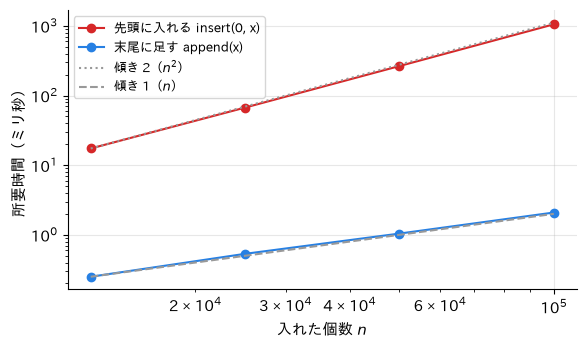

In [6]:
fig, ax = plt.subplots()
ax.plot(sizes, [t * 1000 for t in head_times], "o-",
        label="先頭に入れる insert(0, x)", color="#d62728")
ax.plot(sizes, [t * 1000 for t in tail_times], "o-",
        label="末尾に足す append(x)", color="#2780e3")

# 比べるための補助線。位置は見やすいところに合わせてある
base_n, base_t = sizes[0], head_times[0] * 1000
ax.plot(sizes, [base_t * (n / base_n) ** 2 for n in sizes],
        ls=":", color="#999999", label="傾き 2（$n^2$）")
base_t = tail_times[0] * 1000
ax.plot(sizes, [base_t * (n / base_n) for n in sizes],
        ls="--", color="#999999", label="傾き 1（$n$）")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("入れた個数 $n$")
ax.set_ylabel("所要時間（ミリ秒）")
ax.legend(fontsize=9)
fig.tight_layout()

実測の点が補助線と平行になっている。
これが「$O(n)$ と $O(n^2)$ の違い」の見え方である。

縦軸が対数であることに注意してほしい。
いちばん右では，2 本の線は 2 目盛り以上はなれている。
つまり 100 倍以上の差である。

## 素朴なキューとリングバッファ

もとの話に戻る。キューを配列で素朴に実装すると，
`dequeue` が「先頭を取り出して残りをずらす」になる。
Python では `a.pop(0)` である。

第3回では，これを避けるために**リングバッファ**を使った。
Python の標準ライブラリにある `collections.deque` も，
内側では先頭と末尾の両方を $O(1)$ で扱えるようにしてある。

$n$ 個入れて $n$ 個取り出す，という往復を測って比べる。

In [7]:
import collections


def queue_with_list(n):
    """素朴な実装。先頭の取り出しでそのつど全体をずらす。"""
    q = []
    for i in range(n):
        q.append(i)
    while q:
        q.pop(0)


def queue_with_deque(n):
    """先頭も末尾も O(1) で扱えるキュー。"""
    q = collections.deque()
    for i in range(n):
        q.append(i)
    while q:
        q.popleft()

In [8]:
print(f"{'n':>8}{'list (ms)':>12}{'deque (ms)':>12}{'比':>8}")
for n in (12_500, 25_000, 50_000, 100_000):
    t_list = bench(queue_with_list, n, repeat=1)
    t_deque = bench(queue_with_deque, n, repeat=1)
    print(f"{n:8,d}{t_list * 1000:12.1f}{t_deque * 1000:12.1f}"
          f"{t_list / t_deque:8.0f}")

       n   list (ms)  deque (ms)       比
  12,500        12.9         0.7      20
  25,000        57.1         1.3      43


  50,000       227.2         2.8      81


 100,000       902.2         5.5     164


`list` の列は $n$ を 2 倍にすると約 4 倍になる（$O(n^2)$）。
`deque` の列は約 2 倍である（$O(n)$，1 回あたり $O(1)$）。

$n$ が大きくなるほど差が開く。
これが「オーダーが違う」ということであり，
計算機を速いものに買いかえても埋まらない差である。

## まとめ

- 配列の**先頭**をいじる操作は $O(n)$ である。後ろを全部ずらすからである
- 配列の**末尾**に足す操作はならせば $O(1)$ である
- $n$ 回くりかえすと，前者は $O(n^2)$，後者は $O(n)$ になる
- 実測でも，$n$ を 2 倍にしたとき約 4 倍と約 2 倍になった
- 素朴なキューではなくリングバッファ（や `deque`）を使うのは，この差を避けるためである

$n = 100{,}000$ で数百倍という差は，
「定数倍の話だろう」と片づけられる大きさではない。
**どのデータ構造を選ぶか**が効くのは，こういうところである。

### 自分で試すなら

- `sizes` をもっと大きくするとどうなるか。`push_head` はすぐ数十秒になる
- `a.pop(0)` ではなく `a.pop()`（末尾）にすると，`list` でも速くなるはずである。
  それはどんなデータ構造になっているか
- `insert(0, x)` のかわりに「末尾に足してから最後に `reverse()`」だとどうなるか